In [ ]:
!git clone https://github.com/Cicikuss/Tracks.git

Cloning into 'Tracks'...
remote: Enumerating objects: 18109, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 18109 (delta 0), reused 0 (delta 0), pack-reused 18106 (from 1)
Receiving objects: 100% (18109/18109), 267.89 MiB | 13.24 MiB/s, done.
Updating files: 100% (18104/18104), done.


In [ ]:
!ls Tracks/

driving_log.csv  IMG  README.md


In [ ]:
!pip install imgaug

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.0/948.0 kB 53.6 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Conv2D,MaxPooling2D,Dropout,Flatten,Dense,Convolution2D
import cv2
import matplotlib.image as mpimg
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
import ntpath
import pandas as pd
import random
NP_FLOAT_TYPES = {np.float16, np.float32, np.float64}
NP_INT_TYPES = {np.int8, np.int16, np.int32, np.int64}
NP_UINT_TYPES = {np.uint8, np.uint16, np.uint32, np.uint64}

# Fix NumPy 2.0 incompatibility with imgaug
if not hasattr(np, "sctypes"):
    np.sctypes = {
        "float": [np.float16, np.float32, np.float64],
        "int": [np.int8, np.int16, np.int32, np.int64],
        "uint": [np.uint8, np.uint16, np.uint32, np.uint64],
        "others": [bool, object, str, bytes]
    }

from imgaug import augmenters as iaa

In [ ]:
datadir = "Tracks"
columns = ["center","left","right","steering","throttle","reverse","speed"]
data = pd.read_csv(os.path.join(datadir,"driving_log.csv"),names=columns)
pd.set_option('display.max_colwidth',None)
data.head()

,center,left,right,steering,throttle,reverse,speed
0,/home/engin/Desktop/Data/IMG/center_2026_09_30_17_08_19_099.jpg,/home/engin/Desktop/Data/IMG/left_2026_09_30_17_08_19_099.jpg,/home/engin/Desktop/Data/IMG/right_2026_09_30_17_08_19_099.jpg,0.0,0.0,0.0,0.000079
1,/home/engin/Desktop/Data/IMG/center_2026_09_30_17_08_19_199.jpg,/home/engin/Desktop/Data/IMG/left_2026_09_30_17_08_19_199.jpg,/home/engin/Desktop/Data/IMG/right_2026_09_30_17_08_19_199.jpg,0.0,0.0,0.0,0.000078
2,/home/engin/Desktop/Data/IMG/center_2026_09_30_17_08_19_309.jpg,/home/engin/Desktop/Data/IMG/left_2026_09_30_17_08_19_309.jpg,/home/engin/Desktop/Data/IMG/right_2026_09_30_17_08_19_309.jpg,0.0,0.0,0.0,0.000078
3,/home/engin/Desktop/Data/IMG/center_2026_09_30_17_08_19_419.jpg,/home/engin/Desktop/Data/IMG/left_2026_09_30_17_08_19_419.jpg,/home/engin/Desktop/Data/IMG/right_2026_09_30_17_08_19_419.jpg,0.0,0.0,0.0,0.000078
4,/home/engin/Desktop/Data/IMG/center_2026_09_30_17_08_19_521.jpg,/home/engin/Desktop/Data/IMG/left_2026_09_30_17_08_19_521.jpg,/home/engin/Desktop/Data/IMG/right_2026_09_30_17_08_19_521.jpg,0.0,0.0,0.0,0.000079


In [ ]:
def path_leaf(path):
  head,tail=ntpath.split(path)
  return tail
data['center'] = data['center'].apply(path_leaf)
data['left'] = data['left'].apply(path_leaf)
data['right'] = data['right'].apply(path_leaf)
data.head()

,center,left,right,steering,throttle,reverse,speed
0,center_2026_09_30_17_08_19_099.jpg,left_2026_09_30_17_08_19_099.jpg,right_2026_09_30_17_08_19_099.jpg,0.0,0.0,0.0,0.000079
1,center_2026_09_30_17_08_19_199.jpg,left_2026_09_30_17_08_19_199.jpg,right_2026_09_30_17_08_19_199.jpg,0.0,0.0,0.0,0.000078
2,center_2026_09_30_17_08_19_309.jpg,left_2026_09_30_17_08_19_309.jpg,right_2026_09_30_17_08_19_309.jpg,0.0,0.0,0.0,0.000078
3,center_2026_09_30_17_08_19_419.jpg,left_2026_09_30_17_08_19_419.jpg,right_2026_09_30_17_08_19_419.jpg,0.0,0.0,0.0,0.000078
4,center_2026_09_30_17_08_19_521.jpg,left_2026_09_30_17_08_19_521.jpg,right_2026_09_30_17_08_19_521.jpg,0.0,0.0,0.0,0.000079


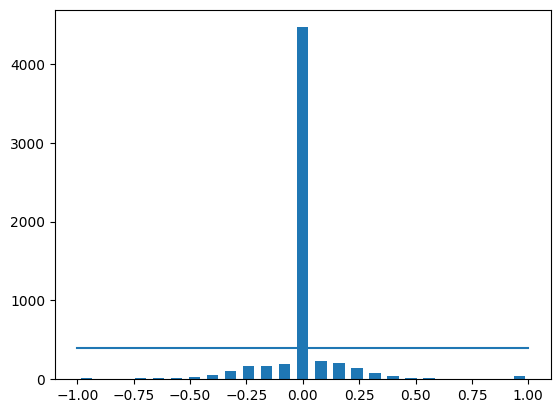

In [ ]:
num_bins = 25
samples_per_bin = 400
hist, bins =np.histogram(data['steering'],num_bins)
center = (bins[:-1]+bins[1:])*0.5
plt.bar(center,hist,width=0.05)
plt.plot((np.min(data['steering']),np.max(data['steering'])),(samples_per_bin,samples_per_bin))

In [ ]:
print("Total data",len(data))
remove_list = []
for i in range(num_bins):
  list_ = []
  for j in range(len(data['steering'])):
    if data['steering'][j] >= bins[i] and data['steering'][j] <= bins[i+1]:
      list_.append(j)
  list_ = shuffle(list_)
  list_ = list_[samples_per_bin:]
  remove_list.extend(list_)

print("Removed",len(remove_list),"elements")
data.drop(data.index[remove_list],inplace=True)
print("Remaining",len(data))

Total data 6034
Removed 4064 elements
Remaining 1970


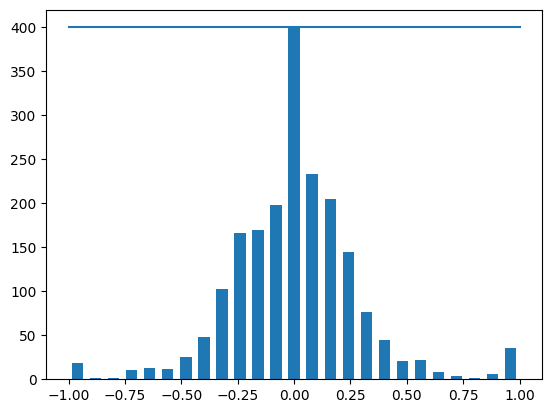

In [ ]:
hist , _ = np.histogram(data['steering'],(num_bins))
plt.bar(center,hist,width=0.05)
plt.plot((np.min(data['steering']),np.max(data['steering'])),(samples_per_bin,samples_per_bin))

In [ ]:
def load_img_steering(datadir,df):
  image_path = []
  steering = []
  for i in range(len(df)):
    indexed_data = df.iloc[i]
    center,left,right = indexed_data[0],indexed_data[1],indexed_data[2]
    image_path.append(os.path.join(datadir,center.strip()))
    steering.append(float(indexed_data[3]))
  image_paths = np.asarray(image_path)
  steerings = np.asarray(steering)
  return image_paths,steerings

In [ ]:
image_paths , steerings = load_img_steering(datadir + '/IMG',data)

/tmp/ipykernel_1102/98049102.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  center,left,right = indexed_data[0],indexed_data[1],indexed_data[2]
/tmp/ipykernel_1102/98049102.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  steering.append(float(indexed_data[3]))


In [ ]:
X_train,X_valid, y_train , y_valid = train_test_split(image_paths,steerings,test_size=0.2,random_state=6)
print("Training Samples: {}\nValid Samples: {}".format(len(X_train),len(X_valid)))

Training Samples: 1576
Valid Samples: 394


Text(0.5, 1.0, 'Validation Set')

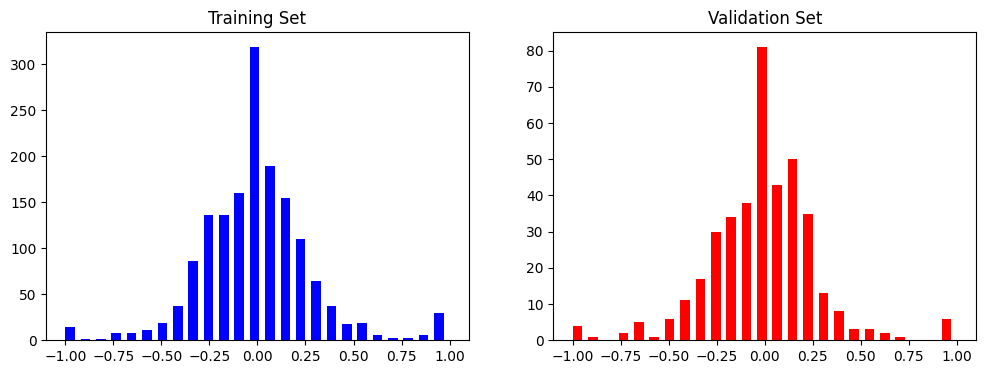

In [ ]:
fig , axis = plt.subplots(1,2,figsize=(12,4))
axis[0].hist(y_train,bins=num_bins,width=0.05,color='blue')
axis[0].set_title('Training Set')
axis[1].hist(y_valid,bins=num_bins,width=0.05,color='red')
axis[1].set_title('Validation Set')


In [ ]:
def zoom(image):
  zoom = iaa.Affine(scale=(1,1.3))
  image = zoom.augment_image(image)
  return image

Text(0.5, 1.0, 'Zoomed Image')

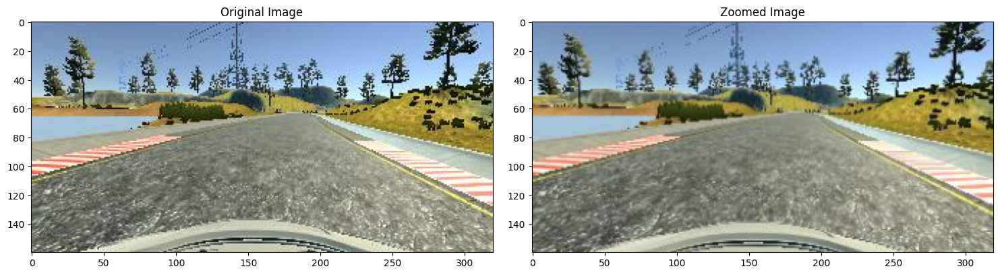

In [ ]:
image = image_paths[random.randint(0,1000)]
original_image = mpimg.imread(image)
zoomed_image = zoom(original_image)

fig,axis = plt.subplots(1,2,figsize=(15,10))
fig.tight_layout()
axis[0].imshow(original_image)
axis[0].set_title('Original Image')
axis[1].imshow(zoomed_image)
axis[1].set_title('Zoomed Image')

In [ ]:
def pan(image):
  pan = iaa.Affine(translate_percent={"x":(-0.1,0.1),"y":(-0.1,0.1)})
  image = pan.augment_image(image)
  return image

Text(0.5, 1.0, 'Panned Image')

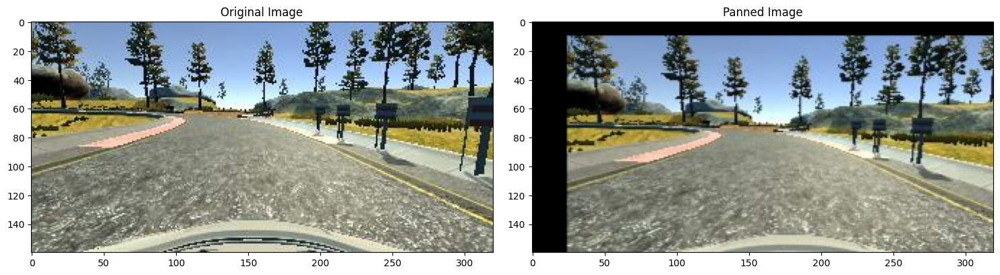

In [ ]:
image = image_paths[random.randint(0,1000)]
original_image = mpimg.imread(image)
panned_image = pan(original_image)

fig,axis = plt.subplots(1,2,figsize=(15,10))
fig.tight_layout()
axis[0].imshow(original_image)
axis[0].set_title('Original Image')
axis[1].imshow(panned_image)
axis[1].set_title('Panned Image')

In [ ]:
def img_random_brightness(image):
  brightness = iaa.Multiply((0.2,1.2))
  image = brightness.augment_image(image)
  return image

Text(0.5, 1.0, 'Brightness Changed Image')

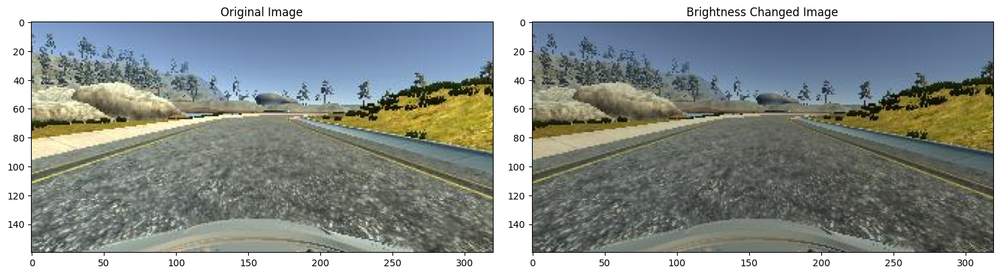

In [ ]:
image = image_paths[random.randint(0,1000)]
original_image = mpimg.imread(image)
brightness_changed_image = img_random_brightness(original_image)

fig,axis = plt.subplots(1,2,figsize=(15,10))
fig.tight_layout()
axis[0].imshow(original_image)
axis[0].set_title('Original Image')
axis[1].imshow(brightness_changed_image)
axis[1].set_title('Brightness Changed Image')

In [ ]:
def image_random_flip(image,steering_angle):
  image = cv2.flip(image,1)
  steering_angle = -steering_angle
  return image,steering_angle

Text(0.5, 1.0, 'Flipped Image Steering Angle:-1.0')

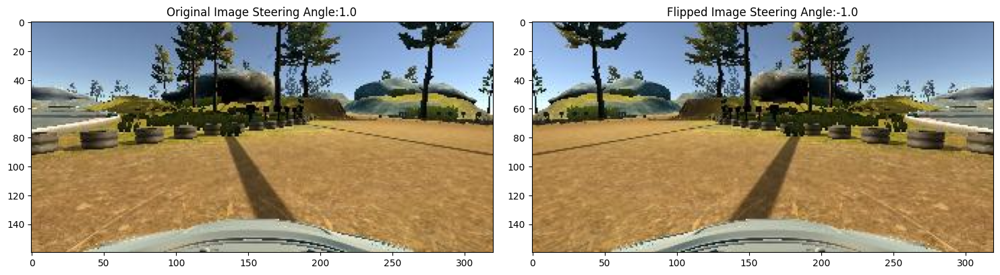

In [ ]:
random_index = random.randint(0,1000)
image = image_paths[random_index]
steering_angle = steerings[random_index]
original_image = mpimg.imread(image)
flipped_image,flipped_steering_angle = image_random_flip(original_image,steering_angle)

fig,axis = plt.subplots(1,2,figsize=(15,10))
fig.tight_layout()
axis[0].imshow(original_image)
axis[0].set_title('Original Image'+' Steering Angle:'+str(steering_angle))

axis[1].imshow(flipped_image)
axis[1].set_title('Flipped Image'+' Steering Angle:'+str(flipped_steering_angle))

In [ ]:
def random_augment(image,steering_angle):
  image = mpimg.imread(image)
  if np.random.rand() < 0.5:
    image = pan(image)
  if np.random.rand() < 0.5:
    image = zoom(image)
  if np.random.rand() < 0.5:
    image = img_random_brightness(image)
  if np.random.rand() < 0.5:
    image,steering_angle = image_random_flip(image,steering_angle)
  return image,steering_angle

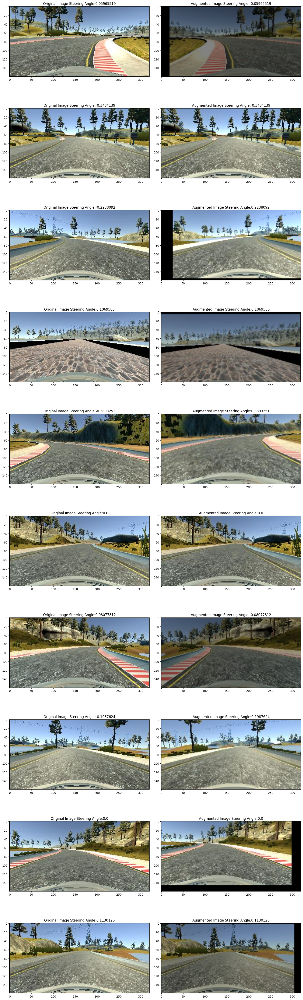

In [ ]:
ncol =2
nrow = 10
fig,axis = plt.subplots(nrow,ncol,figsize=(15,50))
fig.tight_layout()
for i in range(10):
  rand_index = random.randint(0,len(image_paths)-1)
  random_image = image_paths[rand_index]
  random_steering = steerings[rand_index]
  original_image = mpimg.imread(random_image)
  augmented_image,augmented_steering = random_augment(random_image,random_steering)
  axis[i][0].imshow(original_image)
  axis[i][0].set_title('Original Image'+' Steering Angle:'+str(random_steering))
  axis[i][1].imshow(augmented_image)
  axis[i][1].set_title('Augmented Image'+' Steering Angle:'+str(augmented_steering))

In [ ]:
def img_preprocess(img):
  img = img[60:135,:,:]
  img = cv2.cvtColor(img,cv2.COLOR_RGB2YUV)
  img = cv2.GaussianBlur(img,(3,3),0)
  img = cv2.resize(img,(200,66))
  img = img/255
  return img

In [ ]:
image = image_paths[100]
original_image = mpimg.imread(image)
preprocessed_image = img_preprocess(image)

fig,axis = plt.subplots(1,2,figsize=(15,10))
fig.tight_layout()
axis[0].imshow(original_image)
axis[0].set_title('Original Image')
axis[1].imshow(preprocessed_image)
axis[1].set_title('Preprocessed Image')

TypeError: string indices must be integers, not 'tuple'

In [ ]:
def batch_generator(image_paths,steering_ang,batch_size,is_training):
  while True:
    batch_img = []
    batch_steering = []
    for i in range(batch_size):
      random_index = random.randint(0,len(image_paths)-1)
      if is_training:
        im,steering = random_augment(image_paths[random_index],steering_ang[random_index])
      else:
        im = mpimg.imread(image_paths[random_index])
        steering = steering_ang[random_index]
      im = img_preprocess(im)
      batch_img.append(im)
      batch_steering.append(steering)
    yield (np.asarray(batch_img),np.asarray(batch_steering))


Text(0.5, 1.0, 'Validation Image')

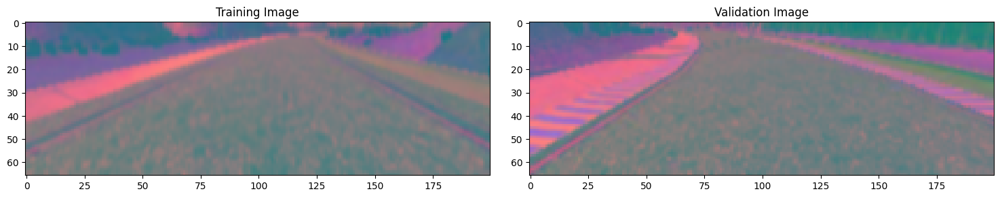

In [ ]:
x_traing_gen,y_train_gen = next(batch_generator(X_train,y_train,1,1))
x_valid_gen,y_valid_gen = next(batch_generator(X_valid,y_valid,1,0))

fig,axis = plt.subplots(1,2,figsize=(15,10))
fig.tight_layout()
axis[0].imshow(x_traing_gen[0])
axis[0].set_title('Training Image')
axis[1].imshow(x_valid_gen[0])
axis[1].set_title('Validation Image')

In [ ]:
def nvidia_model():
  model = Sequential()
  model.add(Convolution2D(24, (5, 5), strides=(2, 2), input_shape=(66, 200, 3), activation='elu'))
  model.add(Convolution2D(36, (5, 5), strides=(2, 2), activation='elu'))
  model.add(Convolution2D(48, (5, 5), strides=(2, 2), activation='elu'))
  model.add(Convolution2D(64, (3, 3), activation='elu'))
  model.add(Convolution2D(64, (3, 3), activation='elu'))
  #model.add(Dropout(0.5))

  model.add(Flatten())
  model.add(Dense(100, activation="elu"))
  #model.add(Dropout(0.5))
  model.add(Dense(50, activation="elu"))
  #model.add(Dropout(0.5))
  model.add(Dense(10, activation="elu"))
  #model.add(Dropout(0.5))
  model.add(Dense(1))

  optimizer = Adam(learning_rate=1e-4)
  model.compile(loss='mse', optimizer=optimizer)
  return model

In [ ]:
model = nvidia_model()
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 31, 98, 24)     │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 47, 36)     │        21,636 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 5, 22, 48)      │        43,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 20, 64)      │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 1, 18, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       115,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,219 (985.23 KB)

 Trainable params: 252,219 (985.23 KB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
history = model.fit(batch_generator(X_train,y_train,100,1),steps_per_epoch=300,epochs = 10,validation_data=batch_generator(X_valid,y_valid,100,0),validation_steps=200,verbose=1,shuffle=1)


Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 145s 452ms/step - loss: 0.0784 - val_loss: 0.0559
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 133s 444ms/step - loss: 0.0684 - val_loss: 0.0508
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 137s 457ms/step - loss: 0.0598 - val_loss: 0.0412
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 131s 438ms/step - loss: 0.0521 - val_loss: 0.0426
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 132s 440ms/step - loss: 0.0482 - val_loss: 0.0370
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 134s 447ms/step - loss: 0.0471 - val_loss: 0.0387
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 124s 416ms/step - loss: 0.0443 - val_loss: 0.0359
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 125s 418ms/step - loss: 0.0433 - val_loss: 0.0353
Epoch 9/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 124s 414ms/step - loss: 0.0418 - val_loss: 0.0369
Epoch 10/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 123s 413ms/step - loss: 0.0414 - val_loss: 0.0321


Text(0.5, 0, 'Epoch')

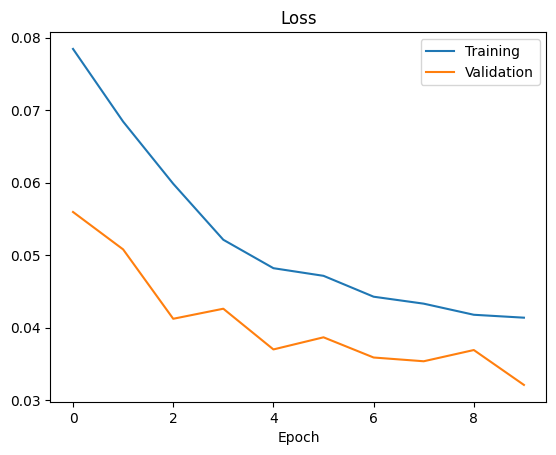

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['Training','Validation'])
plt.title('Loss')
plt.xlabel('Epoch')

In [ ]:
model.save("model.h5")

In [ ]:
from google.colab import files
files.download('model.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.save('model.keras')

In [ ]:
from google.colab import files
files.download('model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>